
# BFT65B – A Big-Data Pipeline for Bank-Failure Early Warning

**Vũ Khánh Hà | Student ID: 11230955**  
**National Economics University**  
**Course: BFT65B – Big Data Analytics in Finance**

**GitHub Repository:** [bft65b-bank-failure](https://github.com/vukhanhhha-101/bft65b-bank-failure)

## Project Overview

This project develops a reproducible big-data pipeline for bank-failure early warning using publicly available financial, failure, and institutional data from the Federal Deposit Insurance Corporation (FDIC).

The pipeline covers quarterly financial reports from 1984Q1 to 2026Q2. It integrates data acquisition, storage optimisation, automated data-quality assessment, bank-quarter panel construction, scalable processing, point-in-time feature engineering, and temporally ordered model validation.

The primary objective is to evaluate the efficiency, reliability, scalability, and reproducibility of the data pipeline rather than simply maximise predictive performance.

## Notebook Structure

| Part | Research Component | Main Scripts |
|---|---|---|
| Part 1 | Acquisition & Storage | `fdic_download_starter.py`, `01b_verify_small_tables.py`, `02_storage.py` |
| Part 2 | Data Quality & Panel Construction | `03_quality.py`, `04_panel.py`, `04b_label_sensitivity.py`, `04c_failure_funnel.py` |
| Part 3 | Scalable Processing | `05_benchmark.py`, `06_spark.py`, `06b_spark_scaleup.py` |
| Part 4 | Feature Pipeline | `07_features.py` |
| Part 5 | Modelling & Validation | `08_model.py`, `08b_lag_sensitivity.py`, `09_mllib.py`, `11_test_descriptives.py` |
| Part 6 | Conclusions & Implications | Research findings, limitations, and implications for Vietnam |

## Reproducibility

Each pipeline stage is implemented as a separate Python script in the `src/` directory. Experimental results, benchmark tables, diagnostic outputs, and model evaluation results are stored in the `reports/` directory.

Package versions are specified in `requirements.txt`, and random seeds are fixed (`SEED = 42`) to support reproducibility.

Raw and processed datasets are generated locally and excluded from GitHub version control.

## Execution Instructions

The notebook is designed to run on Google Colab. If the project directory is unavailable in Google Drive, the notebook clones the public GitHub repository.

- `FORCE = False`: reuse existing outputs where available.
- `FORCE = True`: recompute pipeline stages, excluding the protected test evaluation.
- `RUN_TEST = False`: preserve and display the previously generated test results.

The saved test results are retained to avoid repeated test evaluation during notebook review.

For installation instructions and the complete execution workflow, refer to `README.md` and `run_all.sh`.


## 0. Setup

In [1]:
import os, sys, json, ast, platform, subprocess
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

REPO_URL = "https://github.com/vukhanhhha-101/bft65b-bank-failure.git"
FORCE = False            # True = recompute every step
RUN_TEST = False         # the test period was evaluated once; keep False

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass

# The repository may sit directly in MyDrive or one folder deeper; otherwise clone it.
candidates = [Path("/content/drive/MyDrive/bft65b-bank-failure/bft65b-bank-failure"),
              Path("/content/drive/MyDrive/bft65b-bank-failure"),
              Path("/content/bft65b-bank-failure")]
ROOT = next((p for p in candidates if (p / "src").exists()), None)
if ROOT is None:
    ROOT = candidates[-1]
    subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
os.chdir(ROOT)
REPORTS = ROOT / "reports"


def step(cmd, done=None, force=False):
    """Run one pipeline script (python <cmd>) unless its output file already exists."""
    if done and (ROOT / done).exists() and not (FORCE or force):
        print(f"[skip] {done} exists (FORCE=True recomputes)")
        return
    r = subprocess.run([sys.executable] + list(cmd), cwd=ROOT)
    if r.returncode != 0:
        raise RuntimeError(f"step failed: {' '.join(cmd)}")


def table(name):
    """Show and return a CSV table from reports/."""
    df = pd.read_csv(REPORTS / name)
    display(df)
    return df


print("Repository:", ROOT)
print("Python", platform.python_version(), "|", platform.platform())


Mounted at /content/drive
Repository: /content/drive/MyDrive/bft65b-bank-failure/bft65b-bank-failure
Python 3.13.18 | Linux-6.6.159+-x86_64-with-glibc2.39


In [2]:
!pip install -q -r requirements.txt


In [ ]:
import importlib.metadata as md_
for pkg in ["numpy", "pandas", "polars", "pyarrow", "scikit-learn", "pyspark", "psutil", "matplotlib", "joblib", "requests"]:
    print(f"{pkg:14s}", md_.version(pkg))

numpy          2.4.6
pandas         2.2.3
polars         1.35.2
pyarrow        23.0.1
scikit-learn   1.6.1
pyspark        4.0.5
psutil         5.9.5
matplotlib     3.10.0
joblib         1.6.0
requests       2.32.4


## 1. Acquisition & Storage (Part 1)

**Acquisition.** The course starter script pages through the FDIC `/financials` endpoint quarter by quarter (10,000 rows per call), retries with exponential back-off, writes one Parquet file per quarter and a manifest, so the download is **resumable**. Completeness is checked automatically: rows per quarter must equal the API total and there must be no duplicate (CERT, REPDTE).

In [ ]:
step(["src/fdic_download_starter.py"], done="data_raw/fdic/manifest_financials.json")
man = json.loads((ROOT / "data_raw/fdic/manifest_financials.json").read_text())
ok = sum(m["complete"] for m in man.values())
print(f"quarters: {len(man)} | complete: {ok} | rows: {sum(m['rows'] for m in man.values()):,}")

[skip] data_raw/fdic/manifest_financials.json exists (FORCE=True recomputes)
quarters: 170 | complete: 170 | rows: 1,682,738


**Storage layout.** A fixed schema is enforced and five layouts are compared on the full panel (size, write time, two typical queries). Parquet + zstd partitioned by year is chosen because the study is organised by time.

[skip] reports/storage_benchmark.csv exists (FORCE=True recomputes)


,layout,size_mb,write_s,q_2cols_all_years_s,q_one_year_all_cols_s
0,CSV,446.4,9.87,3.408,3.469
1,Parquet uncompressed,395.4,4.04,0.097,0.386
2,Parquet snappy,209.6,3.73,0.102,0.702
3,Parquet zstd-3,149.2,7.85,0.117,1.054
4,Parquet zstd-3 partitioned by year (CHOSEN),156.3,8.07,0.296,0.086


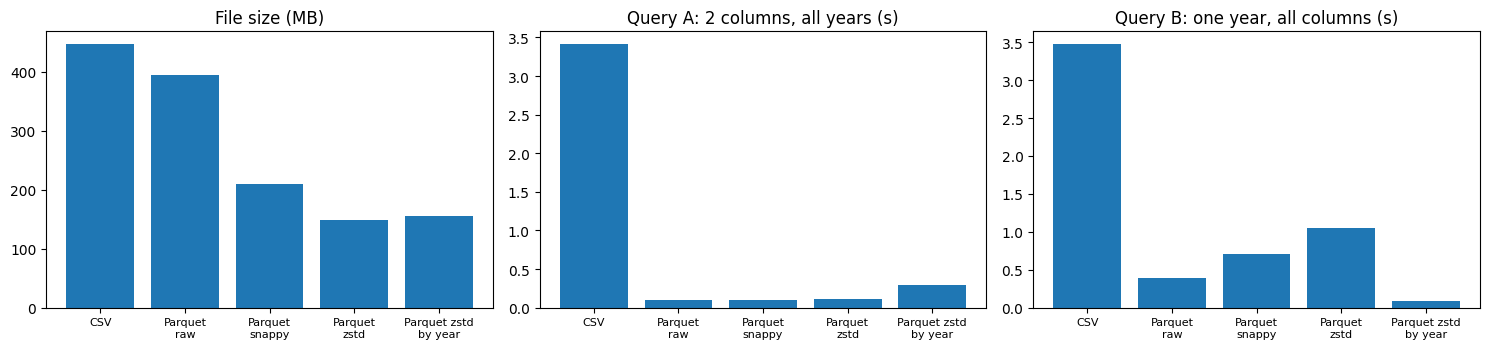

In [ ]:
step(["src/02_storage.py"], done="reports/storage_benchmark.csv")
sb = table("storage_benchmark.csv")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
short = ["CSV", "Parquet\nraw", "Parquet\nsnappy", "Parquet\nzstd", "Parquet zstd\nby year"]
ax[0].bar(short, sb["size_mb"]); ax[0].set_title("File size (MB)")
ax[1].bar(short, sb["q_2cols_all_years_s"]); ax[1].set_title("Query A: 2 columns, all years (s)")
ax[2].bar(short, sb["q_one_year_all_cols_s"]); ax[2].set_title("Query B: one year, all columns (s)")
for a in ax: a.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

## 2. Data Quality & Panel (Part 2)

An automated audit checks completeness, missing values by decade, 12 validity rules, whether flow variables are **year-to-date**, gaps in each bank's history, extreme values and exit types. The panel step then de-cumulates flows, removes reports dated after a failure, labels `y = 1{failure in (q, q+4 quarters]}` (mergers and other exits = 0) and keeps rows up to 2025Q2.

[skip] reports/dq_report.md exists (FORCE=True recomputes)


# Data-quality report (auto-generated by src/03_quality.py)

## 1. Completeness
- quarters: 170; rows: 1,682,738; banks: 24,064
- quarters whose row count != API total: 0
- duplicate (CERT, REPDTE): 0

## 2. Share of missing values by decade
| field | 1980s | 1990s | 2000s | 2010s | 2020s |
|---|---|---|---|---|---|
| ASSET | 0 | 0 | 0 | 0 | 0 |
| DEP | 0 | 1.954e-06 | 0 | 0 | 0 |
| DEPDOM | 0 | 1.954e-06 | 0 | 0 | 0 |
| EQ | 0.001833 | 0.00286 | 0.002152 | 0.002582 | 0.00358 |
| BRO | 0.03189 | 0.002862 | 0.002152 | 0.002582 | 0.00358 |
| CHBAL | 0 | 1.954e-06 | 0 | 0 | 0 |
| SC | 0 | 1.954e-06 | 0 | 0 | 0 |
| LNLSGR | 0 | 1.954e-06 | 0 | 0 | 0 |
| LNLSNET | 0 | 1.954e-06 | 0 | 0 | 0 |
| LNRE | 0 | 1.954e-06 | 0 | 0 | 0 |
| LNCI | 0 | 1.954e-06 | 0 | 0 | 0 |
| LNCON | 0.001337 | 0.002862 | 0.002152 | 0.002582 | 0.00358 |
| LNATRES | 0.001833 | 0.002862 | 0.002152 | 0.002582 | 0.00358 |
| NCLNLS | 0.005952 | 1.954e-06 | 0 | 0 | 0 |
| P3ASSET | 1 | 1 | 0.1112 | 0 | 0 |
| P9ASSET | 0.1853 | 1.954e-06 | 0 | 0 | 0 |
| NAASSET | 0.1853 | 0 | 0 | 0 | 0 |
| NTLNLS | 0.1825 | 0.00286 | 0.002152 | 0.002582 | 0.00358 |
| ORE | 0.001833 | 0.002862 | 0.002152 | 0.002582 | 0.00358 |
| NETINC | 0.00313 | 0.00286 | 0.002152 | 0.002582 | 0.00358 |
| INTINC | 0.00313 | 0.00286 | 0.002152 | 0.002582 | 0.00358 |
| EINTEXP | 0.007289 | 0.00286 | 0.002152 | 0.002582 | 0.00358 |
| NONII | 0.00313 | 0.00286 | 0.002152 | 0.002582 | 0.00358 |
| NONIX | 0.00313 | 0.00286 | 0.002152 | 0.002582 | 0.00358 |
| ELNATR | 0.09488 | 0.00286 | 0.002152 | 0.002582 | 0.00358 |
| ROA | 0 | 0 | 0 | 0 | 0 |
| ROE | 0.02972 | 0.008148 | 0.002229 | 0.002689 | 0.004746 |
| NIMY | 0 | 0 | 0 | 0 | 0 |
| RBC1AAJ | 0 | 0 | 0 | 0 | 0 |
| RBCRWAJ | 0 | 0 | 0 | 0 | 0 |

## 3. Rule violations
| rule | n_rows | pct |
|---|---|---|
| ASSET null or <= 0 | 0 | 0 |
| DEP > ASSET | 6205 | 0.3687 |
| DEPDOM > DEP | 0 | 0 |
| EQ < 0 (negative equity) | 15647 | 0.9299 |
| EQ > ASSET | 1 | 5.943e-05 |
| LNLSNET > ASSET | 2 | 0.0001189 |
| LNLSGR < 0 | 33 | 0.001961 |
| NCLNLS < 0 | 3 | 0.0001783 |
| NCLNLS > LNLSGR | 38 | 0.002258 |
| LNATRES < 0 | 9 | 0.0005348 |
| ROA outside [-100, 100] | 244 | 0.0145 |
| RBC1AAJ outside [-100, 200] | 738 | 0.04386 |

## 4. Are flow variables year-to-date? (rises Mar->Dec = YES, must be de-cumulated)
| month | median_NETINC_over_ASSET |
|---|---|
| 3 | 0.002036 |
| 6 | 0.004217 |
| 9 | 0.006449 |
| 12 | 0.008282 |

## 5. Banks with gaps in their quarterly history
- banks with >=1 missing quarter: 32 of 24,064
- total missing bank-quarters: 92

## 6. Distribution tails
| field | min | p0.1 | p1 | p50 | p99 | p99.9 | max |
|---|---|---|---|---|---|---|---|
| ROA | -761.9 | -22.45 | -5.664 | 0.9745 | 4.163 | 33.15 | 860.6 |
| ROE | -3.547e+05 | -377.1 | -60.14 | 10.34 | 38.95 | 125.5 | 3.01e+05 |
| NIMY | -4515 | -4.592 | 0.2383 | 4.046 | 7.721 | 15.74 | 1125 |
| RBC1AAJ | -1524 | -8.585 | 0 | 9.096 | 68.07 | 104.4 | 4.665e+05 |
| RBCRWAJ | -1.663e+04 | -9.63 | 0 | 13.28 | 109.1 | 496.1 | 2.746e+05 |
| NCLNLS | -1.72e+04 | 0 | 0 | 467 | 1.059e+05 | 1.502e+06 | 6.591e+07 |
| LNATRES | -8.598e+04 | 0 | 0 | 603 | 1e+05 | 1.643e+06 | 3.207e+07 |
| ASSET | 1 | 1596 | 5408 | 8.611e+04 | 1.049e+07 | 1.531e+08 | 4.091e+09 |

## 7. Exits (failure vs other)
| exit_type | len |
|---|---|
| failure | 3241 |
| active | 4306 |
| other_exit | 16517 |

Other exits by CHANGEC1 (map codes with the FDIC dictionary; mergers are NOT failures):
| CHANGEC1 | len |
|---|---|
| 223.0 | 14063 |
| 221.0 | 805 |
| 240.0 | 501 |
| 217.0 | 458 |
|  | 194 |
| 224.0 | 183 |
| 222.0 | 173 |
| 235.0 | 84 |
| 216.0 | 23 |
| 213.0 | 21 |
| 230.0 | 10 |
| 470.0 | 1 |
| 225.0 | 1 |

Failures table by RESTYPE:
| RESTYPE | len |
|---|---|
| FAILURE | 3524 |
| ASSISTANCE | 593 |

- failure records with no Financials rows: 834
- failures whose last report is dated on/after FAILDATE (impossible for point-in-time): 478
- days between last report and FAILDATE: median 47, p10 -163, p90 92


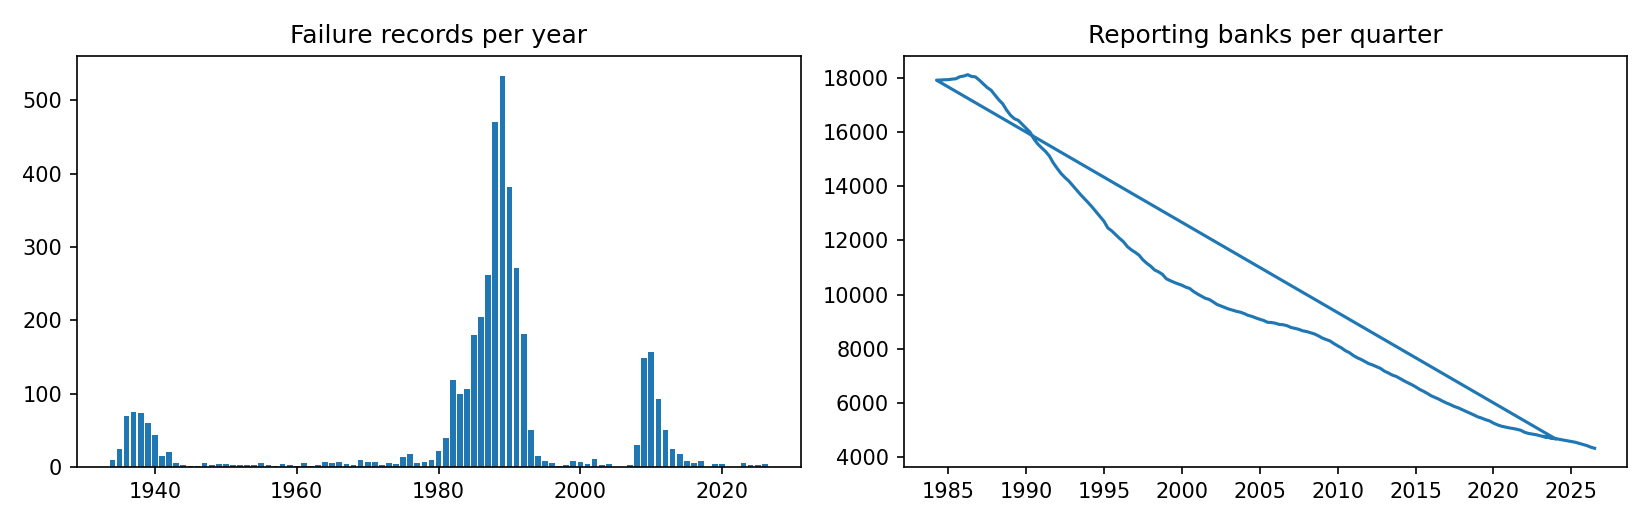

In [ ]:
step(["src/03_quality.py"], done="reports/dq_report.md")
display(Markdown((REPORTS / "dq_report.md").read_text(encoding="utf-8")))
display(Image(filename=str(REPORTS / "dq_overview.png")))

In [ ]:
step(["src/04_panel.py"], done="reports/panel_summary.json")
summary = json.loads((REPORTS / "panel_summary.json").read_text())
display(pd.Series({k: v for k, v in summary.items() if k != "exit_types"}, name="value").to_frame())
display(pd.DataFrame(summary["exit_types"]))
assert summary["test_failed_banks"] >= 50, "the test period must contain at least 50 failures"

[skip] reports/panel_summary.json exists (FORCE=True recomputes)


,value
rows_raw_panel,1682738
rows_dropped_asset_le0,0
rows_dropped_report_after_failure,1211
rows_clean_panel,1681527
rows_modelling_table,1663998
banks,24062
dev_rows,1193798
dev_failed_banks,2290
test_rows,178642
test_failed_banks,469


,EXIT_TYPE,len
0,active,4313
1,failure,2839
2,other_exit,16910


## 3. Scalable Processing (Part 3)

Polars (eager, lazy, streaming) is benchmarked against pandas on three tasks (aggregation, window features, label join) with identical results (checksums), then the data are replicated ×4 and ×8. The key steps are reproduced in PySpark and the results are compared.

In [ ]:
step(["src/05_benchmark.py"], done="reports/benchmark.csv")
bm = table("benchmark.csv")

[skip] reports/benchmark.csv exists (FORCE=True recomputes)


,scale,task,impl,time_median_s,time_min_s,peak_mb,check
0,1,agg,pandas,0.68,0.67,296,0.572994
1,1,agg,polars_eager,0.40,0.39,285,0.572994
2,1,agg,polars_lazy,0.32,0.27,215,0.572994
3,1,agg,polars_streaming,0.22,0.22,165,0.572994
4,1,window,pandas,2.67,2.54,401,0.140757
5,1,window,polars_eager,0.92,0.91,381,0.140757
6,1,window,polars_lazy,0.86,0.85,346,0.140757
7,1,window,polars_streaming,0.89,0.86,327,0.140757
8,1,join,pandas,1.47,0.89,305,10904.000000
9,1,join,polars_eager,0.54,0.51,331,10904.000000


[skip] reports/benchmark_scaleup.csv exists (FORCE=True recomputes)


,scale,task,impl,time_median_s,time_min_s,peak_mb,check
0,1,agg,pandas,1.00,1.00,298,0.572994
1,1,agg,polars_eager,0.61,0.61,286,0.572994
2,1,agg,polars_lazy,0.38,0.38,216,0.572994
3,1,agg,polars_streaming,0.24,0.24,164,0.572994
4,1,window,pandas,2.71,2.71,399,0.140757
5,1,window,polars_eager,0.90,0.90,376,0.140757
6,1,window,polars_lazy,0.85,0.85,341,0.140757
7,1,window,polars_streaming,1.35,1.35,321,0.140757
8,1,join,pandas,1.52,1.52,306,10904.000000
9,1,join,polars_eager,0.52,0.52,331,10904.000000


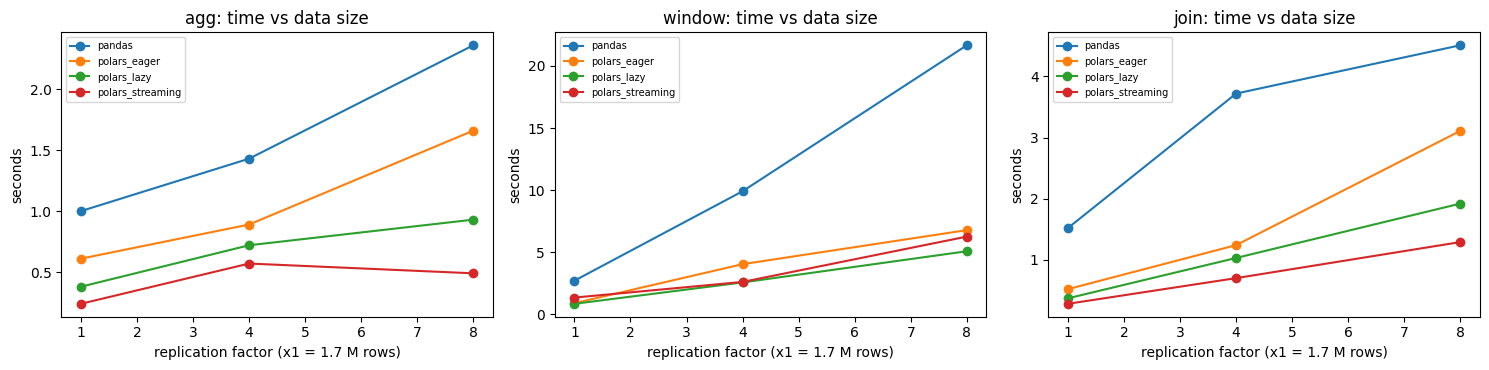

Optimised Polars plan (window task):
SELECT [when([(col("qidx").shift([dyn int: 4]).over([col("CERT")])) == ([(col("qidx")) - (4)])]).then([([(col("ASSET")) / (col("ASSET").shift([dyn int: 4]).over([col("CERT")]))]) - (1.0)]).otherwise(null.cast(Float64)).mean().alias("g"), col("ROA").rolling_mean().over([col("CERT")]).mean().alias("r")]
   WITH_COLUMNS:
   [[([(col("REPDTE").dt.year()) * (4)]) + ([([(col("REPDTE").dt.month()) - (1)]) floor_div (3)].cast(Int32))].alias("qidx")] 
    SORT BY [col("CERT"), col("REPDTE")]
      Parquet SCAN [/content/drive/MyDrive/bft65b-bank-failure/bft65b-bank-failure/data_proc/panel/year=1984/part.parquet, ... 42 other sources]
      PROJECT 4/33 COLUMNS
      ESTIMATED ROWS: 3085680


In [ ]:
step(["src/05_benchmark.py", "--scales", "1", "4", "8", "--reps", "1"], done="reports/benchmark_scaleup.csv")
su = table("benchmark_scaleup.csv")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, task in zip(ax, ["agg", "window", "join"]):
    for impl, g in su[su.task == task].groupby("impl"):
        a.plot(g.scale, g.time_median_s, marker="o", label=impl)
    a.set_title(f"{task}: time vs data size"); a.set_xlabel("replication factor (x1 = 1.7 M rows)"); a.set_ylabel("seconds"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("Optimised Polars plan (window task):"); print((REPORTS / "polars_plan_optimized.txt").read_text())

In [ ]:
# Needs Java (available on Colab). On a laptop without Java, run this step on Colab or Databricks Free Edition.
step(["src/06_spark.py"], done="reports/spark_match.txt")
print((REPORTS / "spark_match.txt").read_text())
table("spark_timing.csv")
print((REPORTS / "spark_plan_window.txt").read_text()[:3000])

[skip] reports/spark_match.txt exists (FORCE=True recomputes)
agg=True
window=True
label_sum=True
spark_y=10904
polars_y=10904



,shuffle_partitions,agg_s,window_s,join_s
0,200,6.07,7.47,4.56
1,16,1.79,4.44,4.75


== Physical Plan ==
AdaptiveSparkPlan (28)
+- == Final Plan ==
   ResultQueryStage (18)
   +- * Sort (17)
      +- AQEShuffleRead (16)
         +- ShuffleQueryStage (15), Statistics(sizeInBytes=1032.0 B, rowCount=43)
            +- Exchange (14)
               +- * HashAggregate (13)
                  +- AQEShuffleRead (12)
                     +- ShuffleQueryStage (11), Statistics(sizeInBytes=4.0 KiB, rowCount=129)
                        +- Exchange (10)
                           +- * HashAggregate (9)
                              +- * Project (8)
                                 +- Window (7)
                                    +- * Sort (6)
                                       +- AQEShuffleRead (5)
                                          +- ShuffleQueryStage (4), Statistics(sizeInBytes=64.1 MiB, rowCount=1.68E+6)
                                             +- Exchange (3)
                                                +- * ColumnarToRow (2)
                                 

## 4. Feature Pipeline (Part 4)

31 point-in-time features in CAMELS groups (capital, asset quality, earnings, liquidity, loan mix and growth, size, dynamics). Lags are **quarter-aware** and use only the past. A truncation test recomputes the features with data up to three cut-off quarters and requires identical values.

In [ ]:
step(["src/07_features.py"], done="reports/pit_test.txt")
print((REPORTS / "pit_test.txt").read_text())
fn = ROOT / "data_proc/feature_names.json"
if fn.exists():
    print(json.loads(fn.read_text()))

[skip] reports/pit_test.txt exists (FORCE=True recomputes)
point-in-time test passed for 3 cut-offs; 1,663,998 rows x 31 features
['log_asset', 'equity_ratio', 'lev_ratio_reg', 'rbc_total', 'loan_ratio', 're_share', 'ci_share', 'con_share', 'npl_ratio', 'pd30_ratio', 'pd90_ratio', 'nonaccrual_ratio', 'ore_ratio', 'reserve_ratio', 'reserve_cover', 'texas_ratio', 'liquidity', 'brokered_ratio', 'deposit_ratio', 'roa', 'roe', 'nim', 'roa_q', 'provision_ratio', 'cost_income', 'asset_growth_4q', 'roa_chg_4q', 'npl_chg_4q', 'equity_chg_4q', 'roa_mean_4q', 'loan_growth_4q']


## 5. Modelling & Validation (Part 5)

**5.1 Split.** Development 1984Q1–2006Q4, gap 2007Q1–2008Q4 (8 quarters), test 2009Q1–2014Q4. **5.2 Validation:** expanding window, 4 folds, 5-quarter purge. **5.3 Metrics:** PR-AUC (primary), ROC-AUC, recall/precision, expected cost. All preprocessing sits in a scikit-learn `Pipeline` fitted on training data only.

In [ ]:
step(["src/08_model.py", "--stage", "dev"], done="reports/dev_summary.json")
display(Markdown("**Pooled out-of-fold PR-AUC / ROC-AUC (development period)**"))
display(pd.read_csv(REPORTS / "cv_pooled.csv", index_col=0))
display(Markdown("**PR-AUC per validation fold**"))
cv = pd.read_csv(REPORTS / "cv_scores.csv")
display(cv.pivot_table(index="model", columns="fold", values="pr_auc").round(3))
dev = json.loads((REPORTS / "dev_summary.json").read_text())
display(pd.Series(dev["cost"], name="cost parameters").to_frame())
display(pd.DataFrame(dev["thresholds"]).T)
_ = table("threshold_sensitivity.csv")

[skip] reports/dev_summary.json exists (FORCE=True recomputes)


**Pooled out-of-fold PR-AUC / ROC-AUC (development period)**

,pr_auc,roc_auc,base_rate
rule_texas_ratio,0.296785,0.776734,0.005018
baseline_logit_4,0.201534,0.959774,0.005018
logit_all,0.286892,0.957651,0.005018
hgb_all,0.341874,0.979260,0.005018


**PR-AUC per validation fold**

fold,1,2,3,4
model,,,,
baseline_logit_4,0.283,0.131,0.211,0.074
hgb_all,0.392,0.343,0.209,0.096
logit_all,0.363,0.190,0.204,0.085
rule_texas_ratio,0.329,0.207,0.147,0.027


,cost parameters
mean_cost_k,54251.820127
rows_per_failure,3.803930
c_miss_row,14262.044322
c_fa_row,50.000000
n_cost_obs,2393.000000


,threshold,alarm_rate,cv_cost_k
baseline_logit_4,0.005952,0.116647,8.823481e+06
logit_all,0.003178,0.075498,9.228125e+06
hgb_all,0.000910,0.081895,6.247941e+06


,c_fa_k,model,threshold,alarm_rate
0,10,logit_all,0.001143,0.304815
1,10,hgb_all,0.000262,0.181649
2,25,logit_all,0.002013,0.141357
3,25,hgb_all,0.000489,0.120938
4,50,logit_all,0.003178,0.075498
5,50,hgb_all,0.000910,0.081895
6,100,logit_all,0.003923,0.058359
7,100,hgb_all,0.001531,0.060367
8,250,logit_all,0.005682,0.039362
9,250,hgb_all,0.003062,0.040935


In [ ]:
# Spark MLlib demo (development data only)
step(["src/09_mllib.py"], done="reports/mllib_demo.csv")
_ = table("mllib_demo.csv")

[skip] reports/mllib_demo.csv exists (FORCE=True recomputes)


,model,pr_auc,roc_auc
0,MLlib logistic,0.018302,0.888944
1,MLlib GBT,0.056589,0.862005


**5.6 Single evaluation on the test period.** The script refuses a second run (`reports/TEST_USED.flag`). With `RUN_TEST = False` this cell only displays the stored result of the run that was made once, after all development decisions were fixed.

,model,pr_auc,roc_auc,base_rate,brier,pr_auc_ci95,recall,precision,alarm_rate,fp,fn,cost_k,cost_no_alarm_k,cost_all_alarm_k
0,rule_texas_ratio,0.493194,0.956545,0.009236,0.302285,"[0.4437101233005128, 0.547349992079473]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,baseline_logit_4,0.626811,0.981795,0.009236,0.006916,"[0.5900973584564729, 0.6738911739896253]",0.958788,0.116050,0.076309,12050.0,68.0,1.572319e+06,2.353237e+07,8849600.0
2,logit_all,0.679449,0.989337,0.009236,0.005733,"[0.64614946998935, 0.7199745666933643]",0.963636,0.150782,0.059029,8955.0,60.0,1.303473e+06,2.353237e+07,8849600.0
3,hgb_all,0.649654,0.990050,0.009236,0.005376,"[0.6065736665698646, 0.6926891709319828]",0.981818,0.088163,0.102859,16755.0,30.0,1.265611e+06,2.353237e+07,8849600.0


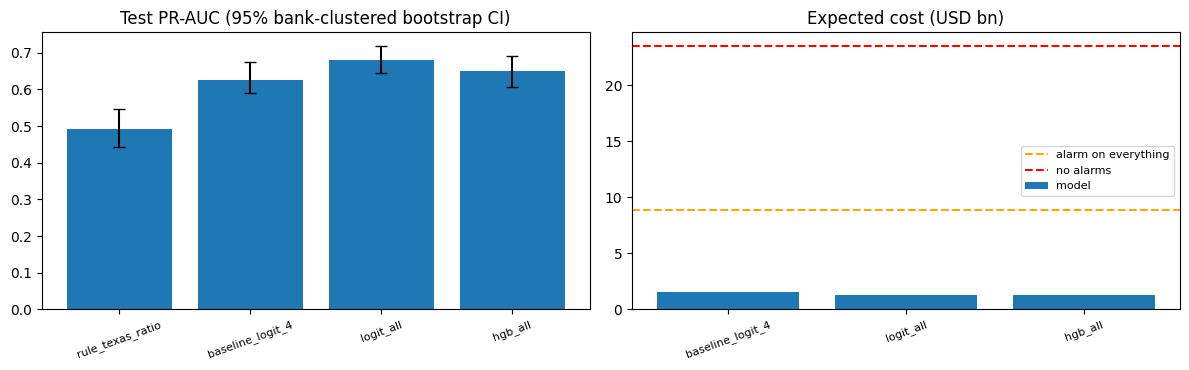

In [ ]:
if RUN_TEST:
    step(["src/08_model.py", "--stage", "test"], force=True)
tr = table("test_results.csv")
tr["ci_lo"] = tr["pr_auc_ci95"].apply(lambda s: ast.literal_eval(s)[0]); tr["ci_hi"] = tr["pr_auc_ci95"].apply(lambda s: ast.literal_eval(s)[1])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(tr.model, tr.pr_auc, yerr=[tr.pr_auc - tr.ci_lo, tr.ci_hi - tr.pr_auc], capsize=4)
ax[0].set_title("Test PR-AUC (95% bank-clustered bootstrap CI)"); ax[0].tick_params(axis="x", rotation=20, labelsize=8)
c = tr.dropna(subset=["cost_k"])
ax[1].bar(c.model, c.cost_k / 1e6, label="model"); ax[1].axhline(c.cost_all_alarm_k.iloc[0] / 1e6, color="orange", ls="--", label="alarm on everything")
ax[1].axhline(c.cost_no_alarm_k.iloc[0] / 1e6, color="red", ls="--", label="no alarms"); ax[1].set_title("Expected cost (USD bn)"); ax[1].legend(fontsize=8)
ax[1].tick_params(axis="x", rotation=20, labelsize=8)
plt.tight_layout(); plt.show()

## 6. Conclusions (Part 6)

**Q1 – Storage and processing.** The 1.68-million-row panel can be processed efficiently on a single machine. Year-partitioned Zstandard Parquet requires 156.3 MB versus 446.4 MB for CSV, reducing storage by approximately 65%. Its one-year query takes 0.098 seconds versus 3.475 seconds for CSV (approximately 35 times faster). Polars is around 3–4 times faster than pandas across the measured workloads. At 8× scale (13.45 million rows), Polars lazy completes the benchmark in 1.36 seconds, compared with 15.22 seconds for Spark local. Spark's overhead makes single-machine Polars more efficient at the current scale; a Spark cluster becomes appropriate when data volume, memory or concurrent processing exceeds local capacity.

**Q2 – Data quality and look-ahead.** Key challenges include historical missingness, cumulative financial flows, extreme observations, reporting gaps, post-failure reports and mixed institutional exit types. The pipeline addresses these through quarterly de-cumulation, validation rules, bank-level reconciliation, FAILURE-only labels and chronological validation. However, reporting dates do not necessarily represent actual information availability. Development lag sensitivity identifies 494 of 4,214 positive observations (11.7%) within 45 days after the reporting date. Excluding them reduces HGB PR-AUC from 0.3419 to 0.3087 and Logistic Regression PR-AUC from 0.2869 to 0.2538. Publication lag therefore remains a material limitation, and the results cannot be considered fully point-in-time validated.

**Q3 – Honest validation.** Development cross-validation favours HistGradientBoosting (PR-AUC 0.342) over 31-feature Logistic Regression (0.287). However, stored 2009–2014 test results show higher PR-AUC for Logistic Regression (0.679) than HGB (0.650), while the Texas-ratio benchmark achieves 0.493. The paired bootstrap difference (HGB minus Logistic) is -0.030 (95% CI: [-0.056, -0.007]). Bank-level recall is approximately 98.9%, with a median warning lead time of 9.8 months. HGB flags 28.7% of non-failing banks at least once, compared with 14.3% for Logistic Regression, illustrating the trade-off between detection and false alarms. The repository records one test evaluation. However, the stored test metrics are not fully publication-lag-adjusted and should be interpreted cautiously rather than as definitive real-time supervisory performance.

**Limitations.** The dataset contains restated rather than exclusively first-filed values, while the assumed 45-day publication delay is not a verified timestamp for every report. The 1,107 observations with failure preceding the assumed publication window may make measured test recall optimistic. Assistance transactions are excluded from the failure definition. False-alarm costs are assumed, and estimated savings represent an upper-bound scenario. Bank-quarter observations are correlated, only one historical crisis period is tested, and P3ASSET has different historical availability across development and test periods. Benchmarks use one Colab machine, and the MLlib demonstration is not fully tuned.

**Implications for Vietnam.** Applying this pipeline requires authorised SBV supervisory data covering financial statements, capital adequacy, liquidity, asset quality and profitability. Features and failure definitions must reflect Vietnamese accounting standards and regulatory classifications. Actual publication timestamps should replace the assumed US 45-day delay. Models and thresholds require recalibration using Vietnamese historical data. Given the limited number of reporting institutions, a local Polars pipeline may be sufficient without a Spark cluster. The system should support supervisory decisions through risk ranking, early-warning signals and explainable indicators, rather than automatically determining institutional failure.

**Overall conclusion.** This project demonstrates that a reproducible financial big-data pipeline can efficiently process 1.68 million rows using single-machine technologies. Its main contribution is the integration of data acquisition, storage optimisation, data-quality auditing, scalable processing, feature engineering and temporal model validation. Publication-lag sensitivity and test-evaluation limitations highlight the importance of information availability and methodological transparency. For Vietnam, the architecture offers a practical foundation for more proactive, data-driven banking supervision, subject to local data access, regulatory adaptation and independent validation.

In [ ]:
!pip freeze | grep -iE "^(numpy|pandas|polars|pyarrow|scikit-learn|pyspark|psutil|matplotlib|joblib|requests)=="

joblib==1.6.0
matplotlib==3.10.0
numpy==2.4.6
pandas==2.2.3
polars==1.35.2
psutil==5.9.5
pyarrow==23.0.1
pyspark==4.0.5
requests==2.32.4
scikit-learn==1.6.1


### Supplemental Robustness & Scalability Checks

In [ ]:
# Supplemental Diagnostics: Label Sensitivity (Part 2c) & PySpark Scale-Up Benchmark (Part 3c)
step(["src/04b_label_sensitivity.py"], done="reports/label_sensitivity.csv")
display(Markdown("**Label Sensitivity & Post-Assistance Continuity (Part 2c)**"))
_ =(table("label_sensitivity.csv"))
_ =(table("assistance_continuity.csv"))

step(["src/06b_spark_scaleup.py", "--scales", "1", "4", "8", "--reps", "1"], done="reports/spark_scaleup.csv")
display(Markdown("**Polars Lazy vs. PySpark Local Scale-Up Benchmark (Part 3c)**"))
display(table("spark_scaleup.csv"))

[skip] reports/label_sensitivity.csv exists (FORCE=True recomputes)


**Label Sensitivity & Post-Assistance Continuity (Part 2c)**

,definition,period,rows,positive_rows,positive_rate,failed_banks
0,FAILURE only (used in the report),development,1193798,8711,0.007297,2290
1,FAILURE only (used in the report),test,178642,1650,0.009236,469
2,FAILURE + ASSISTANCE,development,1193798,10104,0.008464,2651
3,FAILURE + ASSISTANCE,test,178642,1646,0.009214,468
4,ASSISTANCE only,development,1193798,1532,0.001283,396
5,ASSISTANCE only,test,178642,0,0.000000,0


,assisted_banks_in_panel,still_reporting_after_assistance,median_quarters_reported_after
0,437,197,14.961665


[skip] reports/spark_scaleup.csv exists (FORCE=True recomputes)


**Polars Lazy vs. PySpark Local Scale-Up Benchmark (Part 3c)**

,engine,scale,rows,time_median_s,time_min_s,check,match
0,polars_lazy,1,1681527,0.42,0.22,0.140982,True
1,spark_local,1,1681527,2.76,2.58,0.140982,True
2,polars_lazy,4,6726108,0.68,0.63,0.140982,True
3,spark_local,4,6726108,8.31,7.49,0.140982,True
4,polars_lazy,8,13452216,1.23,1.21,0.140982,True
5,spark_local,8,13452216,13.74,13.54,0.140982,True


,engine,scale,rows,time_median_s,time_min_s,check,match
0,polars_lazy,1,1681527,0.42,0.22,0.140982,True
1,spark_local,1,1681527,2.76,2.58,0.140982,True
2,polars_lazy,4,6726108,0.68,0.63,0.140982,True
3,spark_local,4,6726108,8.31,7.49,0.140982,True
4,polars_lazy,8,13452216,1.23,1.21,0.140982,True
5,spark_local,8,13452216,13.74,13.54,0.140982,True


In [ ]:
step(["src/11_test_descriptives.py"], done="reports/test_paired_bootstrap.csv")
_ =table("failure_funnel.csv")
_ =table("test_bank_level.csv")
_ =table("test_paired_bootstrap.csv")

[skip] reports/test_paired_bootstrap.csv exists (FORCE=True recomputes)


,step,count,explanation
0,Records in the Failures table,4117,all RESTYPE values
1,of which RESTYPE = FAILURE,3039,counted as failures in this study
2,of which RESTYPE = ASSISTANCE,593,"assisted banks, not counted as failures"
3,Distinct CERT with a FAILURE record,3036,one bank (CERT) can appear in more than one re...
4,CERT with more than one FAILURE record,3,the earliest FAILDATE is used
5,FAILURE CERT with at least one Financials row,2841,usable for modelling
6,FAILURE CERT without any Financials row,195,no Call Report in 1984Q1-2026Q2
7,of which first FAILDATE before the first q...,189,failed before the data start
8,Banks with exit type 'failure' in the clean panel,2839,"FAILURE CERT with Financials rows, reports bef..."
9,Banks with y = 1 in the development period,2290,label window reaches a failure


,model,failed_banks,caught_banks,bank_recall,lead_median_months,lead_mean_months,share_lead_ge_6m,share_lead_ge_9m,row_alarm_rate,nonfailing_banks_flagged_at_least_once,share_of_nonfailing_banks
0,logit_all,469,463,0.987207,9.724047,8.726724,0.816415,0.710583,0.059029,1135,0.143417
1,hgb_all,469,464,0.989339,9.756899,8.889166,0.834052,0.732759,0.102859,2275,0.287465


,delta_pr_auc_mean,ci95_low,ci95_high,share_of_resamples_gb_better,n_boot
0,-0.030262,-0.056185,-0.006581,0.002,1000


In [ ]:
step(["src/08b_lag_sensitivity.py"], done="reports/dev_lag_sensitivity.csv", force=True)
_ = table("dev_lag_sensitivity.csv")

,sample,model,n_rows,n_pos,pr_auc,roc_auc
0,Dev OOF Full (1989-2006),logit_all,839802,4214,0.2869,0.9577
1,Dev OOF Full (1989-2006),hgb_all,839802,4214,0.3419,0.9793
2,Dev OOF Excl. <=45d Lag,logit_all,839308,3720,0.2538,0.9563
3,Dev OOF Excl. <=45d Lag,hgb_all,839308,3720,0.3087,0.9790
